In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

table = pd.read_parquet("../data/processed/model_table.parquet")
FEATURES = [c for c in table if c not in ("cik", "end") and not c.startswith("y_")]
annee = table["end"].dt.year
table["split"] = np.select([annee <= 2019, annee <= 2021, annee <= 2024],
                           ["train", "val", "test"], default="prediction")

# événement (True/False)  ,  lignes où il est mesurable
EVENEMENTS = {
    "Capitaux propres : perte > 10 % des actifs":
        (table["y_E"] < -0.10,                       table["y_E"].notna()),
    "Trésorerie divisée par 2 ou plus":
        (table["y_C"] < -0.5 * table["C_A"],         table["y_C"].notna() & (table["C_A"] > 0)),
    "Actifs en baisse de plus de 20 %":
        (table["y_A"] < np.log(0.8),                 table["y_A"].notna()),
    "Capitaux propres deviennent négatifs":
        (table["E_A"] + table["y_E"] < 0,            table["y_E"].notna() & (table["E_A"] > 0)),
}

for nom, (evt, ok) in EVENEMENTS.items():
    freq = {s: round(evt[ok & (table["split"] == s)].mean(), 3) for s in ["train", "val", "test"]}
    print(f"{nom:<45} {freq}")

Capitaux propres : perte > 10 % des actifs    {'train': np.float64(0.159), 'val': np.float64(0.189), 'test': np.float64(0.2)}
Trésorerie divisée par 2 ou plus              {'train': np.float64(0.14), 'val': np.float64(0.204), 'test': np.float64(0.152)}
Actifs en baisse de plus de 20 %              {'train': np.float64(0.096), 'val': np.float64(0.123), 'test': np.float64(0.147)}
Capitaux propres deviennent négatifs          {'train': np.float64(0.027), 'val': np.float64(0.043), 'test': np.float64(0.038)}


In [2]:
def top_k(y, p, q=0.10):
    """Taux d'événements parmi les q % d'entreprises jugées les plus risquées."""
    top = p >= np.quantile(p, 1 - q)
    return y[top].mean()

resultats = []
for nom, (evt, ok) in EVENEMENTS.items():
    tr = table[ok & (table["split"] == "train")]
    va = table[ok & (table["split"] == "val")]
    y_tr, y_va = evt[tr.index].astype(int), evt[va.index].astype(int)

    clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                         min_samples_leaf=100, l2_regularization=1.0,
                                         random_state=0)
    clf.fit(tr[FEATURES], y_tr)
    p = clf.predict_proba(va[FEATURES])[:, 1]

    taux_top = top_k(y_va.values, p)
    resultats.append({
        "événement": nom,
        "fréquence": y_va.mean(),
        "AUC modèle": roc_auc_score(y_va, p),
        "AUC règle « en perte »": roc_auc_score(y_va, va["perte"].fillna(0)),
        "AP modèle": average_precision_score(y_va, p),
        "taux dans le top 10 %": taux_top,
        "lift top 10 %": taux_top / y_va.mean(),
    })

pd.DataFrame(resultats).set_index("événement").round(3)

,fréquence,AUC modèle,AUC règle « en perte »,AP modèle,taux dans le top 10 %,lift top 10 %
événement,,,,,,
Capitaux propres : perte > 10 % des actifs,0.189,0.836,0.714,0.497,0.544,2.877
Trésorerie divisée par 2 ou plus,0.204,0.691,0.513,0.380,0.451,2.209
Actifs en baisse de plus de 20 %,0.123,0.808,0.672,0.324,0.363,2.957
Capitaux propres deviennent négatifs,0.043,0.890,0.598,0.237,0.215,5.026


In [3]:
from sklearn.inspection import permutation_importance

importances = {}
for nom, (evt, ok) in EVENEMENTS.items():
    tr = table[ok & (table["split"] == "train")]
    va = table[ok & (table["split"] == "val")]
    clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                         min_samples_leaf=100, l2_regularization=1.0,
                                         random_state=0)
    clf.fit(tr[FEATURES], evt[tr.index].astype(int))
    r = permutation_importance(clf, va[FEATURES], evt[va.index].astype(int),
                               scoring="roc_auc", n_repeats=3, random_state=0, n_jobs=-1)
    importances[nom] = pd.Series(r.importances_mean, index=FEATURES)

imp = pd.DataFrame(importances)
for nom in imp:
    print(f"\n=== {nom} : top 8 ===")
    print(imp[nom].sort_values(ascending=False).head(8).round(4))


=== Capitaux propres : perte > 10 % des actifs : top 8 ===
ROA         0.0279
E_A         0.0149
taille      0.0116
CFO_A       0.0074
RE_A        0.0058
marge_op    0.0043
AC_LC       0.0041
d_L         0.0028
Name: Capitaux propres : perte > 10 % des actifs, dtype: float64

=== Trésorerie divisée par 2 ou plus : top 8 ===
d_C       0.0859
C_A       0.0207
PPE_A     0.0091
taille    0.0087
d_AC      0.0074
AC_A      0.0071
E_A       0.0062
CFF_A     0.0060
Name: Trésorerie divisée par 2 ou plus, dtype: float64

=== Actifs en baisse de plus de 20 % : top 8 ===
ROA         0.0158
taille      0.0150
CFO_A       0.0146
marge_op    0.0126
RE_A        0.0090
PPE_A       0.0072
E_A         0.0069
capex_A     0.0053
Name: Actifs en baisse de plus de 20 %, dtype: float64

=== Capitaux propres deviennent négatifs : top 8 ===
E_A           0.1570
RE_A          0.0246
ROA           0.0122
taille        0.0086
L_A           0.0064
C_A           0.0020
capex_A       0.0020
cout_dette    0.0016
Nam

In [4]:
top = {nom: imp[nom].sort_values(ascending=False).head(8) for nom in imp}
for nom, s in top.items():
    print(f"\n=== {nom} ===")
    print(s.round(4).to_string())


=== Capitaux propres : perte > 10 % des actifs ===
ROA         0.0279
E_A         0.0149
taille      0.0116
CFO_A       0.0074
RE_A        0.0058
marge_op    0.0043
AC_LC       0.0041
d_L         0.0028

=== Trésorerie divisée par 2 ou plus ===
d_C       0.0859
C_A       0.0207
PPE_A     0.0091
taille    0.0087
d_AC      0.0074
AC_A      0.0071
E_A       0.0062
CFF_A     0.0060

=== Actifs en baisse de plus de 20 % ===
ROA         0.0158
taille      0.0150
CFO_A       0.0146
marge_op    0.0126
RE_A        0.0090
PPE_A       0.0072
E_A         0.0069
capex_A     0.0053

=== Capitaux propres deviennent négatifs ===
E_A           0.1570
RE_A          0.0246
ROA           0.0122
taille        0.0086
L_A           0.0064
C_A           0.0020
capex_A       0.0020
cout_dette    0.0016


In [5]:
# Baselines « une seule variable » : est-ce que le modèle apporte plus qu'une règle simple ?
for nom, (evt, ok) in EVENEMENTS.items():
    va = table[ok & (table["split"] == "val")]
    y_va = evt[va.index].astype(int)
    print(f"\n=== {nom} ===")
    for f, sens in [("E_A", -1), ("ROA", -1), ("RE_A", -1), ("d_C", 1)]:
        score = sens * va[f].fillna(va[f].median())
        print(f"  règle « {f} {'faible' if sens < 0 else 'élevé'} » : AUC = {roc_auc_score(y_va, score):.3f}")


=== Capitaux propres : perte > 10 % des actifs ===
  règle « E_A faible » : AUC = 0.340
  règle « ROA faible » : AUC = 0.764
  règle « RE_A faible » : AUC = 0.772
  règle « d_C élevé » : AUC = 0.562

=== Trésorerie divisée par 2 ou plus ===
  règle « E_A faible » : AUC = 0.511
  règle « ROA faible » : AUC = 0.547
  règle « RE_A faible » : AUC = 0.546
  règle « d_C élevé » : AUC = 0.605

=== Actifs en baisse de plus de 20 % ===
  règle « E_A faible » : AUC = 0.409
  règle « ROA faible » : AUC = 0.722
  règle « RE_A faible » : AUC = 0.735
  règle « d_C élevé » : AUC = 0.547

=== Capitaux propres deviennent négatifs ===
  règle « E_A faible » : AUC = 0.779
  règle « ROA faible » : AUC = 0.693
  règle « RE_A faible » : AUC = 0.681
  règle « d_C élevé » : AUC = 0.490


## Synthèse (validation 2020-2021)
| Événement | Fréquence | Meilleure règle simple | AUC modèle | Gain | Lift top 10 % |
|---|---|---|---|---|---|
| Capitaux propres deviennent négatifs | 4,3 % | E_A faible : 0,779 | 0,890 | +0,111 | × 5,0 |
| Perte de capitaux propres > 10 % des actifs | 18,9 % | RE_A faible : 0,772 | 0,836 | +0,064 | × 2,9 |
| Actifs −20 % | 12,3 % | RE_A faible : 0,735 | 0,808 | +0,073 | × 3,0 |
| Trésorerie divisée par 2 | 20,4 % | d_C élevé : 0,605 | 0,691 | +0,086 | × 2,2 |

Features clés : ROA, CFO_A, marge_op (flux) ; E_A, RE_A (bilan) ; d_C (trésorerie).
Interaction notable : E_A élevé + pertes = profil biotech/start-up à risque.

In [6]:
from itertools import product

grille = [dict(learning_rate=lr, max_leaf_nodes=nl, min_samples_leaf=ms)
          for lr, nl, ms in product([0.03, 0.05, 0.1], [15, 31], [50, 100, 300])]

meilleurs = {}
for nom, (evt, ok) in EVENEMENTS.items():
    tr = table[ok & (table["split"] == "train")]
    va = table[ok & (table["split"] == "val")]
    y_tr, y_va = evt[tr.index].astype(int), evt[va.index].astype(int)
    essais = []
    for params in grille:
        clf = HistGradientBoostingClassifier(max_iter=300, l2_regularization=1.0,
                                             random_state=0, **params)
        clf.fit(tr[FEATURES], y_tr)
        essais.append({**params, "AUC": roc_auc_score(y_va, clf.predict_proba(va[FEATURES])[:, 1])})
    essais = pd.DataFrame(essais).sort_values("AUC", ascending=False)
    meilleurs[nom] = essais.iloc[0].drop("AUC").to_dict()
    print(f"\n=== {nom} ===")
    print(essais.head(3).round(4).to_string(index=False))


=== Capitaux propres : perte > 10 % des actifs ===
 learning_rate  max_leaf_nodes  min_samples_leaf    AUC
          0.03              31               100 0.8372
          0.03              31                50 0.8366
          0.05              15                50 0.8364

=== Trésorerie divisée par 2 ou plus ===
 learning_rate  max_leaf_nodes  min_samples_leaf    AUC
          0.10              31                50 0.6922
          0.10              31               100 0.6917
          0.03              31               300 0.6915

=== Actifs en baisse de plus de 20 % ===
 learning_rate  max_leaf_nodes  min_samples_leaf    AUC
          0.05              31               100 0.8079
          0.03              31                50 0.8071
          0.03              31               100 0.8063

=== Capitaux propres deviennent négatifs ===
 learning_rate  max_leaf_nodes  min_samples_leaf    AUC
          0.03              15               300 0.9042
          0.05              15    

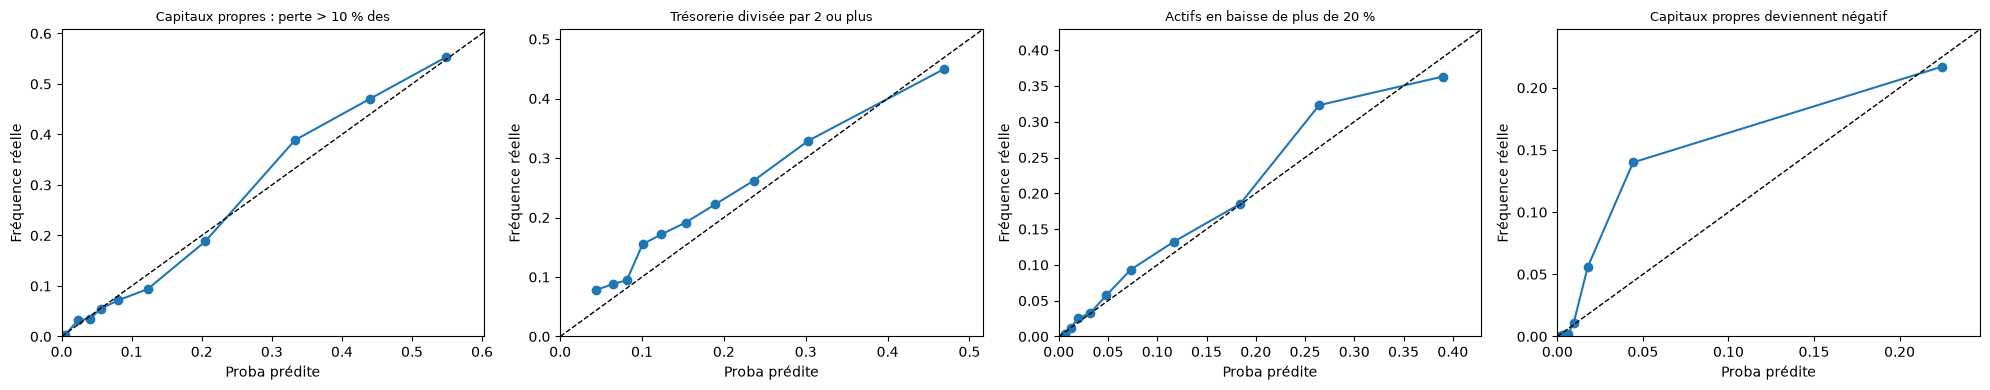

,AUC,IC 95 % bas,IC 95 % haut,AUC 2020,AUC 2021,fréquence,proba moyenne
événement,,,,,,,
Capitaux propres : perte > 10 % des actifs,0.837,0.827,0.846,0.788,0.880,0.189,0.185
Trésorerie divisée par 2 ou plus,0.692,0.678,0.707,0.681,0.716,0.204,0.176
Actifs en baisse de plus de 20 %,0.808,0.796,0.818,0.780,0.839,0.123,0.115
Capitaux propres deviennent négatifs,0.904,0.894,0.914,0.876,0.929,0.043,0.032


In [7]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
bilan = []
for ax, (nom, (evt, ok)) in zip(axes, EVENEMENTS.items()):
    tr = table[ok & (table["split"] == "train")]
    va = table[ok & (table["split"] == "val")]
    y_tr, y_va = evt[tr.index].astype(int), evt[va.index].astype(int).values
    clf = HistGradientBoostingClassifier(max_iter=300, l2_regularization=1.0, random_state=0,
                                         **{k: (int(v) if k != "learning_rate" else v)
                                            for k, v in meilleurs[nom].items()})
    clf.fit(tr[FEATURES], y_tr)
    p = clf.predict_proba(va[FEATURES])[:, 1]

    # 1) Intervalle de confiance à 95 % de l'AUC (bootstrap : 300 rééchantillonnages)
    aucs = []
    for _ in range(300):
        i = rng.integers(0, len(p), len(p))
        if y_va[i].min() != y_va[i].max():
            aucs.append(roc_auc_score(y_va[i], p[i]))
    # 2) Stabilité par année
    an = va["end"].dt.year.values
    auc_an = {a: round(roc_auc_score(y_va[an == a], p[an == a]), 3) for a in np.unique(an)}

    bilan.append({"événement": nom, "AUC": roc_auc_score(y_va, p),
                  "IC 95 % bas": np.percentile(aucs, 2.5), "IC 95 % haut": np.percentile(aucs, 97.5),
                  **{f"AUC {a}": v for a, v in auc_an.items()},
                  "fréquence": y_va.mean(), "proba moyenne": p.mean()})

    # 3) Calibration : probabilité prédite contre fréquence réelle, par décile
    dec = pd.qcut(p, 10, labels=False, duplicates="drop")
    cal = pd.DataFrame({"pred": p, "reel": y_va, "dec": dec}).groupby("dec").mean()
    ax.plot(cal["pred"], cal["reel"], "o-"); ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlim(0, cal["pred"].max() * 1.1); ax.set_ylim(0, max(cal["reel"].max(), cal["pred"].max()) * 1.1)
    ax.set_title(nom[:35], fontsize=9); ax.set_xlabel("Proba prédite"); ax.set_ylabel("Fréquence réelle")
plt.tight_layout(); plt.show()
pd.DataFrame(bilan).set_index("événement").round(3)

In [8]:
groupes = {
    "Petites (< 100 M$)":         lambda d: d["taille"] < 8,
    "Moyennes (100 M$ - 10 Md$)": lambda d: d["taille"].between(8, 10),
    "Grandes (> 10 Md$)":         lambda d: d["taille"] > 10,
    "Sans actif courant (banques, assurances)": lambda d: d["AC_A"].isna(),
}
lignes = []
for nom, (evt, ok) in EVENEMENTS.items():
    tr = table[ok & (table["split"] == "train")]
    va = table[ok & (table["split"] == "val")]
    clf = HistGradientBoostingClassifier(max_iter=300, l2_regularization=1.0, random_state=0,
                                         **{k: (int(v) if k != "learning_rate" else v)
                                            for k, v in meilleurs[nom].items()})
    clf.fit(tr[FEATURES], evt[tr.index].astype(int))
    p = pd.Series(clf.predict_proba(va[FEATURES])[:, 1], index=va.index)
    for g, cond in groupes.items():
        m = cond(va)
        y = evt[va.index][m].astype(int)
        if m.sum() > 100 and 0 < y.mean() < 1:
            lignes.append({"événement": nom[:35], "groupe": g, "n": int(m.sum()),
                           "AUC": roc_auc_score(y, p[m])})
pd.DataFrame(lignes).pivot(index="groupe", columns="événement", values="AUC").round(3)

événement,Actifs en baisse de plus de 20 %,Capitaux propres : perte > 10 % des,Capitaux propres deviennent négatif,Trésorerie divisée par 2 ou plus
groupe,,,,
Grandes (> 10 Md$),0.715,0.786,0.950,0.726
Moyennes (100 M$ - 10 Md$),0.811,0.842,0.920,0.706
Petites (< 100 M$),0.713,0.709,0.827,0.611
"Sans actif courant (banques, assurances)",0.836,0.886,0.979,0.653


## Vérifications avant le test (validation 2020-2021)

**A. Réglage des hyperparamètres** (18 combinaisons, critère : AUC sur la validation)
- Gains quasi nuls (≤ 0,001) sauf « capitaux propres deviennent négatifs » : 0,890 → 0,904,
  avec des arbres plus simples (15 feuilles, ≥ 300 entreprises par feuille) → moins de surapprentissage sur un événement rare.
- Conclusion : le modèle n'est pas le facteur limitant.

**B. Fiabilité**
| Événement | AUC | IC 95 % | AUC 2020 | AUC 2021 |
|---|---|---|---|---|
| Capitaux propres deviennent négatifs | 0,904 | 0,894 – 0,914 | 0,876 | 0,929 |
| Perte de capitaux propres > 10 % | 0,837 | 0,827 – 0,846 | 0,788 | 0,880 |
| Actifs −20 % | 0,808 | 0,796 – 0,818 | 0,780 | 0,839 |
| Trésorerie divisée par 2 | 0,692 | 0,678 – 0,707 | 0,681 | 0,716 |

- Intervalles étroits (±0,01) → gains sur les règles simples (+0,06 à +0,11) significatifs.
- 2020 plus difficile (bilans 2020 → année de sortie du COVID).
- Calibration : bonne pour « perte > 10 % » et « actifs −20 % » ; sous-estimation pour la trésorerie
  et les capitaux propres négatifs (fréquence plus élevée en validation qu'en train).
- **Décision : le score final utilisera le rang (percentile), plus robuste que la probabilité brute.**

**C. Sous-groupes**
- Entreprises moyennes et grandes : AUC 0,71 à 0,95.
- Petites entreprises (< 100 M$) : plus difficiles (0,61 à 0,83) → limite à annoncer.
- Banques/assurances : scores très élevés mais peu d'événements → à interpréter avec prudence.

**Configuration figée pour le test** : 30 features, meilleurs réglages (A), règles de comparaison choisies sur la validation,
apprentissage sur train + validation (≤ 2021).